## Начальный EDA (KION)

**Импорты**

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
pd.set_option("display.max_columns", None)

**Загрузка и обзор данных**

In [3]:
users = pd.read_csv("../data/raw/users_en.csv")
items = pd.read_csv("../data/raw/items_en.csv")
interactions = pd.read_csv("../data/raw/interactions.csv")

### Пользователи, сводка

In [4]:
display(users.head())
print(f"Размерность таблицы:\n{users.shape}")
print(f"\nКол-во пропусков:\n{users.isna().sum()}")

,Unnamed: 0,user_id,age,income,sex,kids_flg
0,0,973171,age_25_34,income_60_90,M,1
1,1,962099,age_18_24,income_20_40,M,0
2,2,1047345,age_45_54,income_40_60,F,0
3,3,721985,age_45_54,income_20_40,F,0
4,4,704055,age_35_44,income_60_90,F,0


Размерность таблицы:
(840197, 6)

Кол-во пропусков:
Unnamed: 0        0
user_id           0
age           14095
income        14776
sex           13831
kids_flg          0
dtype: int64


### Айтемы, сводка

In [5]:
display(items.head())
print(f"Размерность таблицы:\n{items.shape}")
print(f"\nКол-во пропусков:\n{items.isna().sum()}")

,Unnamed: 0,item_id,content_type,title,title_orig,release_year,genres,countries,for_kids,age_rating,studios,description,keywords,actors_translated,actors_transliterated,directors_translated,transliterated
0,0,10711,film,Talk to her,Hable con ella,2002.0,"drama, foreign, detective, melodrama",Spain,NaN,16.0,NaN,"Marco, a journalist, interviews the famous Tor...","Talk, her, 2002, Spain, friends, love, strong,...","Adolfo Fernández, Ana Fernández, Dario Grandin...","Adol'fo Fernandes, Ana Fernandes, Dario Grandi...",Pedro Almodovar,Pedro Al'modovar
1,1,2508,film,Naked Peppers,Search Party,2014.0,"foreign, adventure, comedy",USA,NaN,16.0,NaN,The main character has learned not to invite h...,"Naked, Peppers, 2014, USA, friends, weddings, ...","Adam Palley, Brian Huskey, JB Smoove, Jason Ma...","Adam Palli, Brajan Haski, Dzh.B. Smuv, Dzhejso...",Scott Armstrong,Skot Armstrong
2,2,10716,film,Tactical force,Tactical Force,2011.0,"crime, foreign, thrillers, action, comedy",Canada,NaN,16.0,NaN,"Professional wrestler Steve Austin (""All or No...","Tactical, Force, 2011, Canada, bandits, gangst...","Adrian Holmes, Darren Shalavi, Jerry Wasserman...","Adrian Holms, Darren Shalavi, Dzherri Vasserma...",Adam P. Caltraro,Adam P. Kaltraro
3,3,7868,film,45 years old,45 Years,2015.0,"drama, foreign, melodrama",UK,NaN,16.0,NaN,"Charlotte Rampling, Tom Courtney, Geraldine Ja...","45, years, 2015, United Kingdom, marriage, lif...","Alexandra Riddleston-Barrett, Geraldine James,...","Aleksandra Riddlston-Barrett, Dzheral'din Dzhe...",By Andrew Hay,Endrju Hej
4,4,16268,film,Everything Solves in a Moment,NaN,1978.0,"drama, sport, soviet, melodrama",USSR,NaN,12.0,Lenfilm,The circle of her mentors and the most loyal f...,"Everything that decides, moment, 1978, USSR, s...","Aleksandr Abdulov, Aleksandr Demyanenko, Alexe...","Aleksandr Abdulov, Aleksandr Dem'janenko, Alek...",Victor Sadovsky,Viktor Sadovskij


Размерность таблицы:
(15963, 17)

Кол-во пропусков:
Unnamed: 0                   0
item_id                      0
content_type                 0
title                        2
title_orig                4745
release_year                98
genres                       0
countries                    0
for_kids                 15397
age_rating                   2
studios                  14898
description                  0
keywords                   429
actors_translated         2619
actors_transliterated     2619
directors_translated      1524
transliterated            1509
dtype: int64


### Взаимодействия, сводка

In [6]:
display(interactions.head())
print(f"Размерность таблицы:\n{interactions.shape}")
print(f'\nТипы данных столбов:\n{interactions.dtypes}')
print(f"\nКол-во пропусков:\n{interactions.isna().sum()}")

,user_id,item_id,last_watch_dt,total_dur,watched_pct
0,176549,9506,2021-05-11,4250,72.0
1,699317,1659,2021-05-29,8317,100.0
2,656683,7107,2021-05-09,10,0.0
3,864613,7638,2021-07-05,14483,100.0
4,964868,9506,2021-04-30,6725,100.0


Размерность таблицы:
(5476251, 5)

Типы данных столбов:
user_id            int64
item_id            int64
last_watch_dt     object
total_dur          int64
watched_pct      float64
dtype: object

Кол-во пропусков:
user_id            0
item_id            0
last_watch_dt      0
total_dur          0
watched_pct      828
dtype: int64


**Самые популярные items**

In [7]:
top_items = (interactions.groupby('item_id')
                  .size()
                  .sort_values(ascending=False)
                  .head(100))

print(top_items.head(10))

item_id
10440    202457
15297    193123
9728     132865
13865    122119
4151      91167
3734      74803
2657      68581
4880      55043
142       45367
6809      40372
dtype: int64


**Сводка непосредственно о watched_pcd**

In [8]:
interactions["watched_pct"].describe()

count    5.475423e+06
mean     4.637400e+01
std      4.191853e+01
min      0.000000e+00
25%      4.000000e+00
50%      3.200000e+01
75%      1.000000e+02
max      1.000000e+02
Name: watched_pct, dtype: float64

**Сводка о всех пользователях сервиса**

In [9]:
user_counts = interactions.groupby('user_id').size()
item_counts = interactions.groupby('item_id').size()

print("Пользователи")
print(user_counts.describe())

Пользователи
count    962179.000000
mean          5.691510
std          10.886262
min           1.000000
25%           1.000000
50%           2.000000
75%           6.000000
max        1341.000000
dtype: float64


# Смешные графики

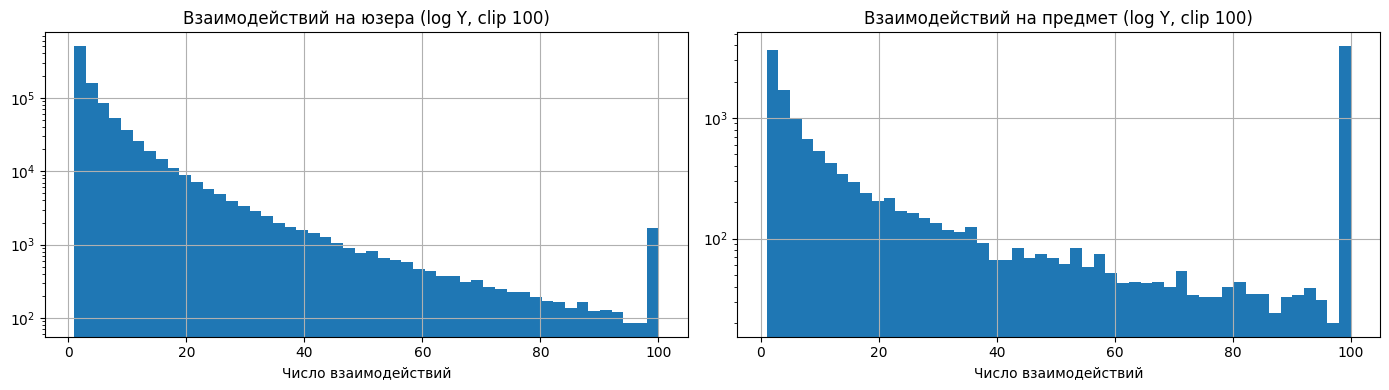

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))

user_counts.clip(upper=100).hist(bins=50, ax=axes[0], log=True)
axes[0].set_title('Взаимодействий на юзера (log Y, clip 100)')
axes[0].set_xlabel('Число взаимодействий')

item_counts.clip(upper=100).hist(bins=50, ax=axes[1], log=True)
axes[1].set_title('Взаимодействий на предмет (log Y, clip 100)')
axes[1].set_xlabel('Число взаимодействий')

plt.tight_layout()
plt.show()

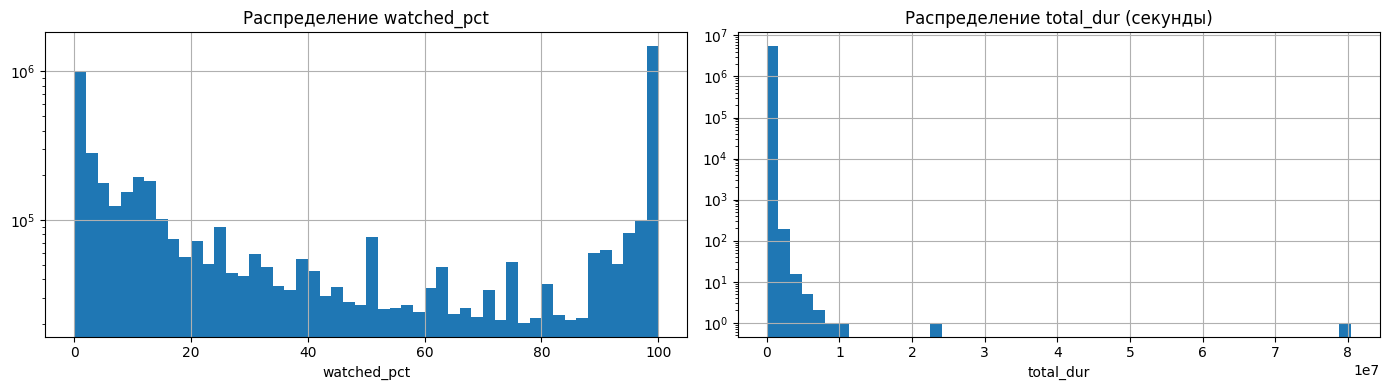

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))

interactions['watched_pct'].hist(bins=50, ax=axes[0])
axes[0].set_title('Распределение watched_pct')
axes[0].set_xlabel('watched_pct')
axes[0].set_yscale('log')

interactions['total_dur'].hist(bins=50, ax=axes[1])
axes[1].set_title('Распределение total_dur (секунды)')
axes[1].set_xlabel('total_dur')
axes[1].set_yscale('log')
plt.tight_layout()
plt.show()

Мин. дата: 2021-03-13 00:00:00
Макс. дата: 2021-08-22 00:00:00
Всего дней: 162


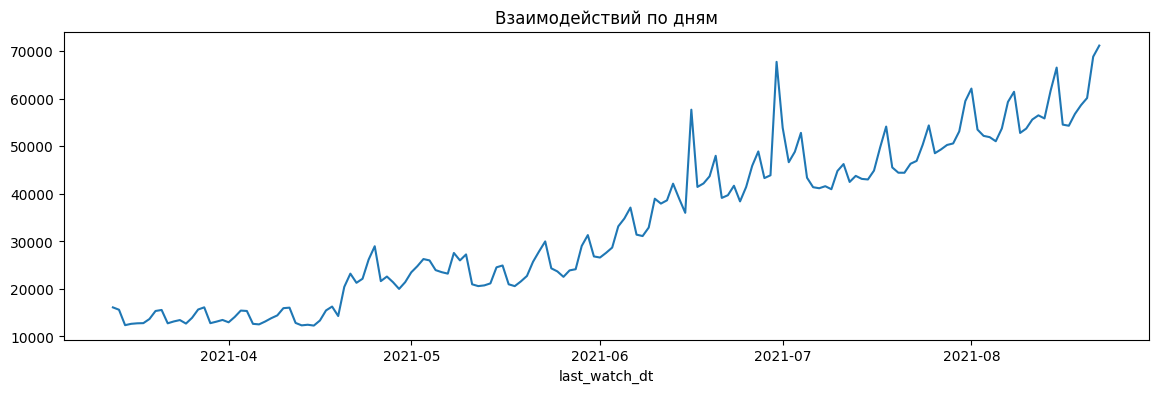

In [12]:
interactions['last_watch_dt'] = pd.to_datetime(interactions['last_watch_dt'])
print("Мин. дата:", interactions['last_watch_dt'].min())
print("Макс. дата:", interactions['last_watch_dt'].max())
print("Всего дней:", (interactions['last_watch_dt'].max() - 
                       interactions['last_watch_dt'].min()).days)

# Распределение по дням
daily = interactions.groupby(interactions['last_watch_dt'].dt.date).size()
daily.plot(figsize=(14, 4), title='Взаимодействий по дням')
plt.show()